# Arc-limited low thrust: fixing the deorbit shape mismatch

Flying a deorbit with low thrust hides something easy to get wrong: a continuous tangential burn sized to match an impulsive deorbit's delta-v reaches the same final semi-major axis, since the same propellant buys the same orbital energy change regardless of how the thrust is steered, but it does not reach the same final shape. It spirals the orbit down nearly circularly instead of producing the impulsive burn's eccentric transfer orbit, so the resulting perigee never actually drops into the atmosphere at the intended altitude. `mission_budget.ipynb` later meets this same mismatch on the disposal burn of the full mission.

This notebook fixes that, using `low_thrust_arc_tangential_dynamics_symbolic`, which only fires the thrust within an angular arc around a fixed point in the orbit rather than continuously. Narrowing that arc concentrates the same propellant's delta-v into less and less of each orbit, building eccentricity instead of just spreading energy evenly, and interpolates smoothly between the already-studied continuous limit (`half_angle = pi`, firing the whole orbit) and the impulsive limit (`half_angle -> 0`, a brief burn concentrated at one point).

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import MU_EARTH, R_EARTH
from ios_mission_planner.dynamics.orbital.maneuvers import hohmann_transfer
from ios_mission_planner.dynamics.orbital.low_thrust_design import (
    arc_duty_cycle, deorbit_with_arc_limited_thrust, solve_half_angle_for_target_perigee,
)
from ios_mission_planner.budget.propellant import initial_mass

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"


## Setup

The scenario is the disposal burn of the reference mission, the one `mission_budget.ipynb` budgets later: a 500 km circular chief, a target perigee altitude of 200 km, a 150 kg dry mass, 1800 s specific impulse (electric propulsion), and a 0.2 N thruster. The equivalent impulsive burn's delta-v, from the same `hohmann_transfer` used throughout this project, is what sizes the propellant mass for every arc width tested below, so the comparison always spends the identical propellant.

In [2]:
alt_chief = 500.0
a_c = R_EARTH + alt_chief
v_circ = np.sqrt(MU_EARTH / a_c)
chief0 = np.array([a_c, 0.0, 0.0, 0.0, v_circ, 0.0])

r_perigee_target = R_EARTH + 200.0
dv_deorbit, _, _ = hohmann_transfer(a_c, r_perigee_target, MU_EARTH)
dv_deorbit_ms = abs(dv_deorbit) * 1e3

m_dry, isp, thrust = 150.0, 1800.0, 0.2
m0 = initial_mass(dv_deorbit_ms, isp, m_dry)

print(f"target dv: {dv_deorbit_ms:.3f} m/s, target perigee altitude: {r_perigee_target - R_EARTH:.1f} km")
print(f"propellant mass for this dv: {m0 - m_dry:.4f} kg (m0={m0:.4f} kg)")


target dv: 85.338 m/s, target perigee altitude: 200.0 km
propellant mass for this dv: 0.7269 kg (m0=150.7269 kg)


## Sweeping the arc width

For a handful of half-angles from a full orbit down to a narrow arc, propagate the burn to propellant depletion and record the final semi-major axis and the final perigee altitude.

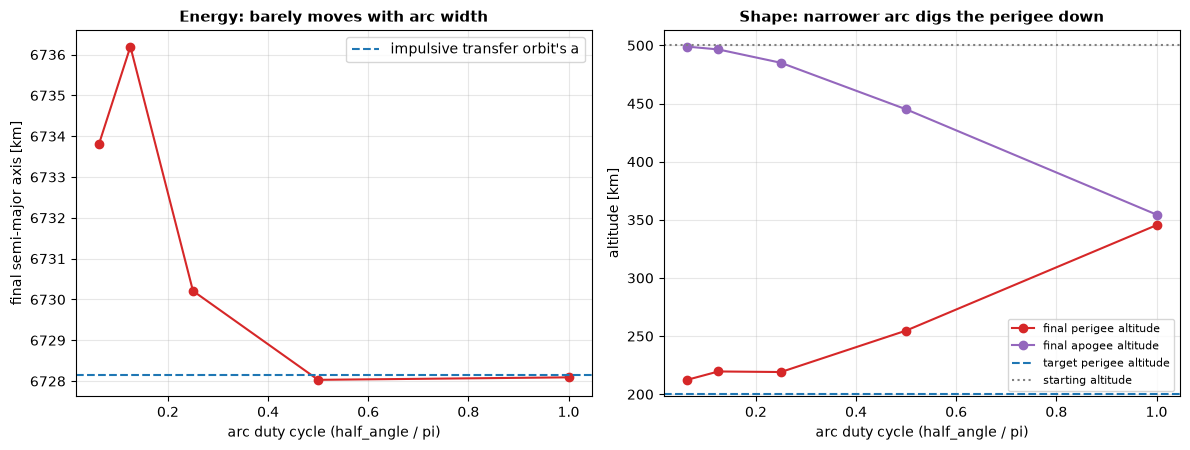

In [3]:
half_angles = np.array([np.pi, np.pi/2, np.pi/4, np.pi/8, np.pi/16])
finals_a, finals_rp, finals_ra = [], [], []

for half_angle in half_angles:
    elements, _ = deorbit_with_arc_limited_thrust(
        chief0, half_angle, dv_deorbit_ms, m_dry, isp, thrust, MU_EARTH, n_pts=2000,
    )
    finals_a.append(elements.a)
    finals_rp.append(elements.a * (1 - elements.e) - R_EARTH)
    finals_ra.append(elements.a * (1 + elements.e) - R_EARTH)

finals_a, finals_rp, finals_ra = np.array(finals_a), np.array(finals_rp), np.array(finals_ra)
duty = arc_duty_cycle(half_angles)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

axes[0].plot(duty, finals_a, "o-", color=COL_NUM)
axes[0].axhline(0.5 * (a_c + r_perigee_target), color=COL_ANA, ls="--", label="impulsive transfer orbit's a")
axes[0].set_xlabel("arc duty cycle (half_angle / pi)")
axes[0].set_ylabel("final semi-major axis [km]")
axes[0].set_title("Energy: barely moves with arc width")
axes[0].legend()

axes[1].plot(duty, finals_rp, "o-", color=COL_NUM, label="final perigee altitude")
axes[1].plot(duty, finals_ra, "o-", color=COL_ZONE, label="final apogee altitude")
axes[1].axhline(200.0, color=COL_ANA, ls="--", label="target perigee altitude")
axes[1].axhline(500.0, color="gray", ls=":", label="starting altitude")
axes[1].set_xlabel("arc duty cycle (half_angle / pi)")
axes[1].set_ylabel("altitude [km]")
axes[1].set_title("Shape: narrower arc digs the perigee down")
axes[1].legend(fontsize=8)

fig.tight_layout()

The left panel is the part that stays almost fixed: the final semi-major axis sits close to the impulsive transfer orbit's value across every arc width, confirming once more that the propellant buys the same orbital energy regardless of how it is spread around the orbit. The right panel is the part that does not: the final perigee altitude drops steadily as the arc narrows, and the apogee altitude climbs back up toward the original 500 km, which is exactly the eccentric transfer-orbit shape a single impulsive burn would have produced, being approached continuously as the thrust arc shrinks toward a point.

## Solving for the arc that hits the target exactly

Rather than reading an approximate answer off the sweep above, `solve_half_angle_for_target_perigee` bisects directly on the half-angle to hit the target perigee radius, for the same fixed propellant budget.

In [4]:
half_angle, r_p_reached = solve_half_angle_for_target_perigee(
    chief0, r_perigee_target, dv_deorbit_ms, m_dry, isp, thrust, MU_EARTH, tol=0.5,
)

elements, result = deorbit_with_arc_limited_thrust(
    chief0, half_angle, dv_deorbit_ms, m_dry, isp, thrust, MU_EARTH, n_pts=4000,
)
perigee_alt = elements.a * (1 - elements.e) - R_EARTH
apogee_alt = elements.a * (1 + elements.e) - R_EARTH

print(f"solved half_angle: {half_angle:.4f} rad ({np.degrees(half_angle):.2f} deg), "
      f"duty cycle {arc_duty_cycle(half_angle):.3f}")
print(f"final orbit: a={elements.a:.2f} km, e={elements.e:.5f}, "
      f"perigee altitude={perigee_alt:.2f} km, apogee altitude={apogee_alt:.2f} km")

solved half_angle: 0.0712 rad (4.08 deg), duty cycle 0.023
final orbit: a=6727.65 km, e=0.02229, perigee altitude=199.56 km, apogee altitude=499.47 km


A thrust arc only a few degrees wide, centered on a single fixed point of the original circular orbit, reaches a perigee altitude within about a kilometre of the 200 km target, with an apogee altitude close to the original 500 km, the same shape the impulsive deorbit burn was designed to produce, built here entirely out of continuous low-thrust propulsion with no instantaneous burns anywhere.

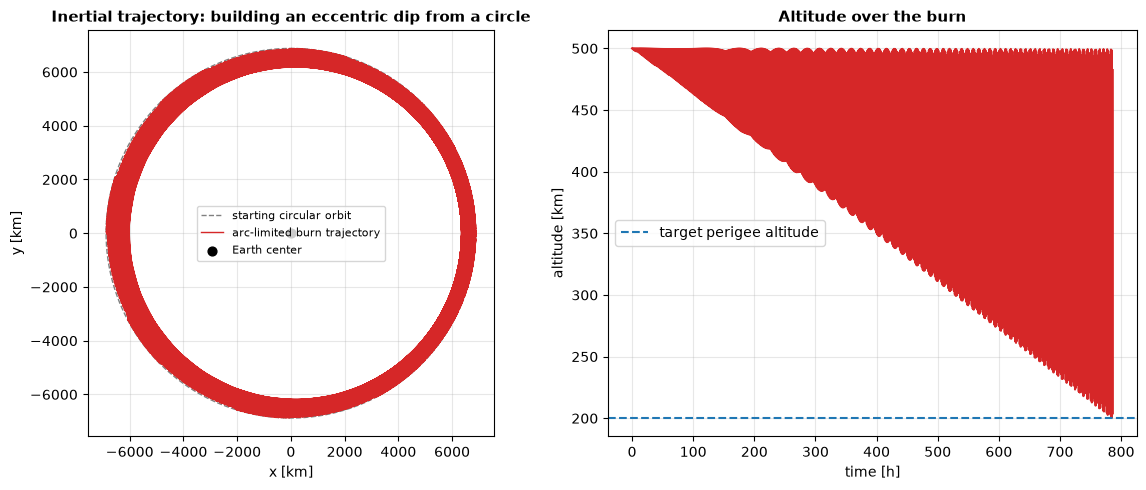

In [5]:
r = np.linalg.norm(result.y[:3, :], axis=0)
x, y = result.y[0, :], result.y[1, :]
t_hours = result.t / 3600.0

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

theta = np.linspace(0, 2 * np.pi, 400)
axes[0].plot(a_c * np.cos(theta), a_c * np.sin(theta), "--", color="gray", lw=1, label="starting circular orbit")
axes[0].plot(x, y, color=COL_NUM, lw=1, label="arc-limited burn trajectory")
axes[0].scatter([0], [0], color="k", marker="o", s=40, label="Earth center")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x [km]"); axes[0].set_ylabel("y [km]")
axes[0].set_title("Inertial trajectory: building an eccentric dip from a circle")
axes[0].legend(fontsize=8)

axes[1].plot(t_hours, r - R_EARTH, color=COL_NUM)
axes[1].axhline(200.0, color=COL_ANA, ls="--", label="target perigee altitude")
axes[1].set_xlabel("time [h]"); axes[1].set_ylabel("altitude [km]")
axes[1].set_title("Altitude over the burn")
axes[1].legend()

fig.tight_layout()

## The accuracy-versus-time trade-off, as a Pareto front

The bisection above finds a single answer: the half-angle that gets closest to the target perigee, full stop. That is not always the question worth asking. A narrower arc gets closer to the target, but `arc_duty_cycle` means it also takes proportionally longer in wall-clock time to spend the same propellant, and a mission with a tight schedule might prefer a faster, less exact burn over a slower, nearly perfect one. This is a genuine two-objective trade-off, perigee accuracy against burn duration, and `pareto_front_arc_half_angle` evolves it directly with [pygmo](https://esa.github.io/pygmo2/)'s NSGA-II multi-objective algorithm rather than collapsing it into the single bisection target used above.

fastest burn in the front: 17.8 h, perigee error 145.3 km
most accurate in the front: 786.1 h, perigee error 0.0 km


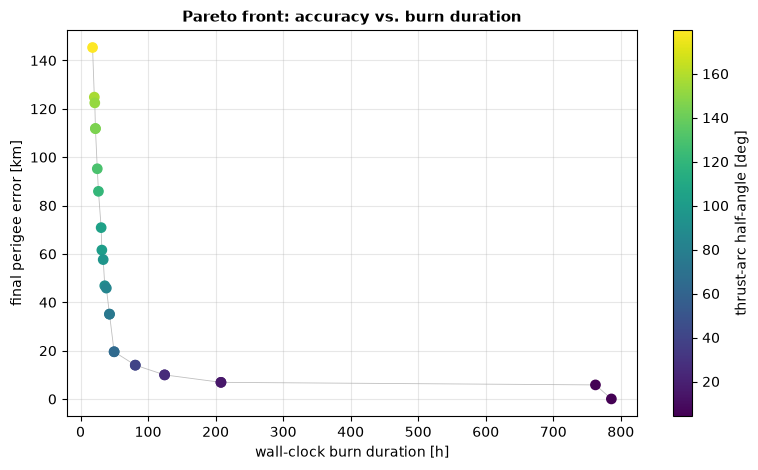

In [6]:
from ios_mission_planner.dynamics.orbital.low_thrust_design import pareto_front_arc_half_angle

half_angles_pf, perigee_errors_pf, wall_times_pf = pareto_front_arc_half_angle(
    chief0, r_perigee_target, dv_deorbit_ms, m_dry, isp, thrust, MU_EARTH,
    generations=30, pop_size=24, seed=42,
)

order = np.argsort(wall_times_pf)
fig, ax = plt.subplots(figsize=(8, 4.8))
sc = ax.scatter(wall_times_pf[order] / 3600.0, perigee_errors_pf[order],
                 c=np.degrees(half_angles_pf[order]), cmap="viridis", s=45)
ax.plot(wall_times_pf[order] / 3600.0, perigee_errors_pf[order], color="gray", lw=0.6, alpha=0.5, zorder=0)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("thrust-arc half-angle [deg]")
ax.set_xlabel("wall-clock burn duration [h]")
ax.set_ylabel("final perigee error [km]")
ax.set_title("Pareto front: accuracy vs. burn duration")
fig.tight_layout()

print(f"fastest burn in the front: {wall_times_pf[order][0]/3600:.1f} h, "
      f"perigee error {perigee_errors_pf[order][0]:.1f} km")
print(f"most accurate in the front: {wall_times_pf[order][-1]/3600:.1f} h, "
      f"perigee error {perigee_errors_pf[order][-1]:.1f} km")

Every point on this curve is a genuinely different, non-dominated choice: nothing in the evolved population reaches both a shorter burn and a smaller perigee error than another point on the same curve, which is exactly what makes it a Pareto front rather than just a scatter of results. The bisection solution from the previous section sits at the accurate, slow end of this same trade-off, since it was built to minimize perigee error alone with no regard for how long the burn takes; NSGA-II instead hands back the whole family of reasonable compromises around it, which is the more useful answer whenever burn duration is itself a mission constraint, not just an afterthought.

## Summary

Matching an impulsive burn's delta-v with continuous low thrust matches its energy but not automatically its purpose, as the sweep above shows for a deorbit. This notebook closes that gap with one extra idea on top of the already-validated tangential steering: throttle the thrust on only within a fixed arc of the orbit instead of running it continuously. Sweeping the arc width shows the semi-major axis staying essentially pinned to the impulsive transfer orbit's value throughout, while the final perigee altitude slides continuously from the continuous-thrust limit down toward the impulsive one as the arc narrows, and a simple bisection on the arc half-angle lands within about a kilometre of the actual 200 km target, for the exact same propellant budget that, spread continuously, missed it by roughly 150 km of altitude.

The idealization worth stating plainly: the thrust arc here is centered on a single fixed inertial direction, chosen once, which works because an unperturbed two-body orbit's apsidal line does not itself drift during the burn. A real implementation would still need onboard logic to recognize and hold that arc as the orbit evolves, and the bisection above assumes, rather than proves, that a wider arc always means a higher final perigee; that held cleanly for every case tried here, but is not a guarantee for every possible chief orbit or thrust level.

A second idealization sits in the wall-clock time estimate itself, and it is worth being equally plain about it: `arc_duty_cycle` assumes every orbit spends the same fraction of its time inside the arc, which is only approximately true once the orbit has already become noticeably eccentric from many earlier passes through that same arc. Pushed to arcs far narrower than anything used above, this estimate drifts enough that the final semi-major axis stops staying pinned to the impulsive transfer orbit's value, the signature that the approximation has broken down rather than that the underlying physics has changed. The arc width this notebook actually solves for, a few degrees wide, sits comfortably inside the regime where the estimate holds; an arc much narrower than that would need a sturdier timing scheme, not just a smaller number plugged into the same formula.

The same problem also exposes a real trade-off pygmo is better suited to than a bisection: burn duration against perigee accuracy, evolved above as a Pareto front with NSGA-II rather than collapsed into one target, handing a mission designer the whole family of reasonable compromises instead of a single answer.